# `find_outer_region`

Finds void voxels that lie outside the solid porous sample using a rolling-ball method. This is useful for non-rectangular samples such as cylindrical cores or irregular rock fragments.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import porespy as ps

ps.visualization.set_mpl_style()

## `im`

Create a circular porous sample surrounded by open void space (represented by `True`) and identify the exterior region:

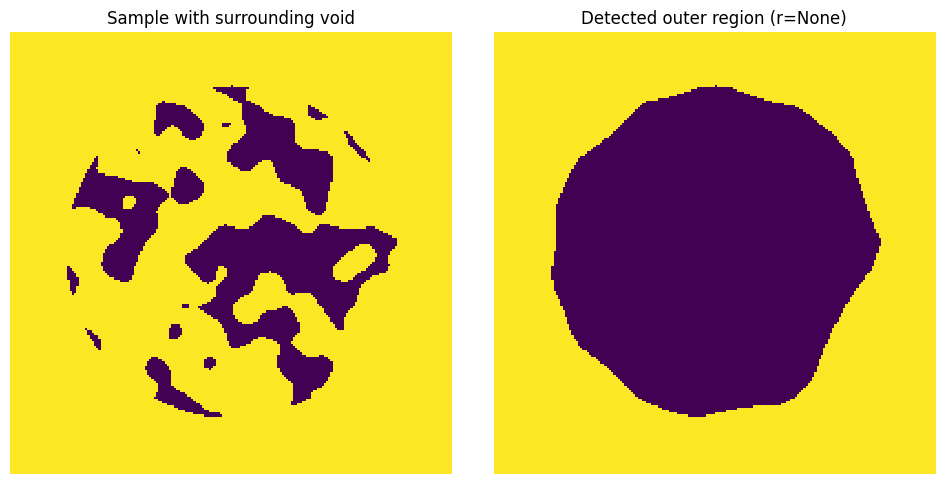

In [2]:
im = ps.generators.blobs(shape=[200, 200], porosity=0.6, seed=0)
# Keep only the porous sample inside a circular core; set exterior to True (void)
y, x = np.ogrid[:200, :200]
core = (x - 100) ** 2 + (y - 100) ** 2 <= 75 ** 2
im_sample = np.where(core, im, True)

outer = ps.tools.find_outer_region(im=im_sample)

fig, ax = plt.subplots(1, 2, figsize=[10, 5])
ax[0].imshow(im_sample, origin="lower", interpolation="none")
ax[0].set_title("Sample with surrounding void")
ax[0].axis(False)
ax[1].imshow(outer, origin="lower", interpolation="none")
ax[1].set_title("Detected outer region (r=None)")
ax[1].axis(False);

## `r`

The `r` parameter sets the radius of the rolling ball. A smaller radius allows the ball to enter larger surface pores, whereas a larger radius bridges across surface openings:

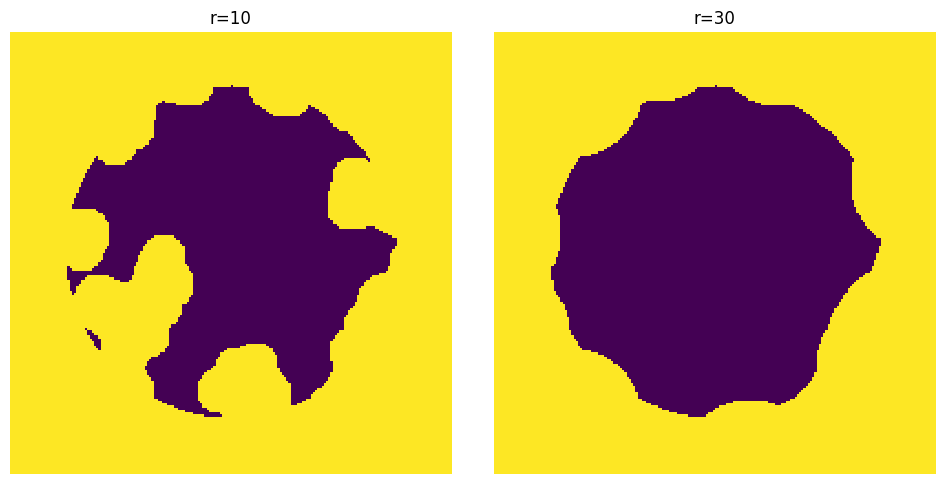

In [3]:
outer_small = ps.tools.find_outer_region(im=im_sample, r=10)
outer_large = ps.tools.find_outer_region(im=im_sample, r=30)

fig, ax = plt.subplots(1, 2, figsize=[10, 5])
ax[0].imshow(outer_small, origin="lower", interpolation="none")
ax[0].set_title("r=10")
ax[0].axis(False)
ax[1].imshow(outer_large, origin="lower", interpolation="none")
ax[1].set_title("r=30")
ax[1].axis(False);